# Dermoscopy Copilot — 03. Passive Learning Baseline with Test-Time Augmentation

**Course:** Human-Centered Artificial Intelligence (HCAI) · MSc in Biomedical Engineering · University of Coimbra
· **Group 13:** Carolina Garrido, Sara Santos, Sara Seco

## Purpose of this notebook

This notebook trains and evaluates the passive learning baseline, a supervised classifier trained on 100% of the labelled training split. It is the upper reference against which the active learning query strategies (least confidence, margin, entropy) and random sampling will later be compared through learning curves.

The classifier is a single **linear layer** (`D → 7`) trained on the frozen features extracted in notebook `02_feature_extraction.ipynb` using the `tf_efficientnetv2_s.in21k_ft_in1k` CNN backbone across the 7 HAM10000 skin lesion categories (akiec, bcc, bkl, df, mel, nv, vasc). Key methodological choices:

- **Class imbalance:** the loss is weighted with *balanced* class weights, computed on the original (non-augmented) training images;
- **Model selection:** early stopping on the macro F1-score of the validation set to prevent majority classes from dominating checkpoint selection;
- **Test-Time Augmentation (TTA):** in validation and test, the prediction is the **mean of the probabilities** across all $V = 8$ views of each image;
- **Calibration:** *temperature scaling* is fitted on the validation set, on top of the averaged probability, to align model confidence with true empirical accuracy;
- **Ablation:** results are also reported **without TTA** (original view only), to quantify the gain brought by TTA.

**Prerequisite:** the `features_<BACKBONE>/` folder produced by notebook `02_feature_extraction.ipynb`.

## 1. Library imports

In [16]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from IPython.display import Image as IPImage, display
from sklearn.metrics import (balanced_accuracy_score, confusion_matrix, f1_score,
                             precision_score, recall_score, roc_auc_score)
from sklearn.utils.class_weight import compute_class_weight

## 2. Configuration

`BACKBONE` is set to `tf_efficientnetv2_s.in21k_ft_in1k`, which must match notebook 02 so that the corresponding feature archive is loaded and outputs are saved under `results_<BACKBONE>/`.

The linear classifier is trained for up to `EPOCHS` (100) epochs using the Adam optimizer with a learning rate (`LR`) of `1e-3` and L2 regularization (`WEIGHT_DECAY`) of `1e-4`. Training uses a `BATCH` size of `256` feature vectors, because the model operates directly on pre-extracted embeddings rather than raw images, large mini-batches remain computationally lightweight while stabilizing gradient updates. Early stopping monitors the validation macro F1-score and halts training after `PATIENCE` (`10`) consecutive epochs without improvement. Finally, `SEED` is fixed at `42` to guarantee reproducible weight initialization and mini-batch shuffling.

`RETRAIN` controls whether the baseline is trained again: if `False` (default) and the saved results already exist in the results folder, they are loaded instead; if `True`, the baseline is trained from scratch and the saved files are overwritten.

In [17]:
BACKBONE = "tf_efficientnetv2_s.in21k_ft_in1k"   # must match BACKBONE in notebook 02

# Base path: go up one level if the notebook is inside the 'notebooks' folder
BASE_DIR = Path("..") if Path.cwd().name == "notebooks" else Path(".")
FEATS = BASE_DIR / "features" / f"features_{BACKBONE}"
OUT = BASE_DIR / "results" / "results_baseline" / f"results_{BACKBONE}"
OUT.mkdir(exist_ok=True)

RETRAIN = False  # True = train the baseline again, even if saved results exist

CLASSES = ["akiec", "bcc", "bkl", "df", "mel", "nv", "vasc"]
MEL = CLASSES.index("mel")
SEED = 42
EPOCHS = 100
PATIENCE = 10
BATCH = 256
LR = 1e-3
WEIGHT_DECAY = 1e-4

torch.manual_seed(SEED)
np.random.seed(SEED)

# Saved results of the baseline (if they exist, there is nothing to train or evaluate)
use_saved = (not RETRAIN) and all(
    (OUT / f).exists()
    for f in ["baseline_metrics.json", "baseline_head.pt", "baseline_confusion_matrix.png"]
)
print("Results folder:", OUT)
print("Saved results found (they will be loaded):", use_saved)

Results folder: ..\results\results_baseline\results_tf_efficientnetv2_s.in21k_ft_in1k
Saved results found (they will be loaded): True


## 3. Auxiliary functions

- `carregar`: loads the pre-extracted feature tensor (`X`), integer class labels (`y`) and augmentation indices (`aug_idx`) of a split.
- `logits_vistas`: applies the linear classification head to every view; `(N, V, D) → (N, V, C)`.
- `probs_tta`: softmax (optionally divided by a temperature `T`) followed by the **mean over views**; `(N, V, C) → (N, C)`.
- `ajustar_temperatura`: *temperature scaling*. Finds the temperature `T` that minimises the negative log-likelihood (NLL) on the validation set, using L-BFGS.
- `ece`: **Expected Calibration Error**, which measures the gap between the model's confidence and its actual accuracy (15 bins).
- `avaliar`: computes the evaluation metrics: Balanced Accuracy, macro-averaged Precision, Recall (sensitivity), F1-score and AUC, plus the recall of melanoma and the recall per class. Sensitivity is given particular attention, since false negatives in malignant lesions such as melanoma have important clinical consequences.
- `avaliar_config`: fits `T` on the validation set and evaluates on the test set, using whichever views are passed in.

In [18]:
def carregar(split):
    d = np.load(FEATS / f"{split}_features.npz", allow_pickle=True)
    return (torch.tensor(d["X"], dtype=torch.float32),
            torch.tensor(d["y"], dtype=torch.long),
            d["aug_idx"])


def logits_vistas(head, X):
    # X: (N, V, D) -> logits (N, V, C)
    N, V, D = X.shape
    return head(X.reshape(N * V, D)).reshape(N, V, -1)


def probs_tta(logits, T=1.0):
    # Mean of the probabilities of the V views. logits: (N, V, C) -> (N, C)
    return F.softmax(logits / T, dim=2).mean(dim=1)


def ajustar_temperatura(logits, y):
    # Temperature scaling on the mean probability of the views (NLL on validation).
    # Optimize log_T so that T = exp(log_T) remains strictly positive
    log_T = torch.zeros(1, requires_grad=True)
    opt = torch.optim.LBFGS([log_T], lr=0.1, max_iter=100)

    def closure():
        opt.zero_grad()
        p = probs_tta(logits, log_T.exp())
        loss = F.nll_loss(torch.log(p + 1e-12), y)
        loss.backward()
        return loss

    opt.step(closure)
    return float(log_T.exp())


def ece(probs, y, n_bins=15):
    conf, pred = probs.max(1)
    acerto = (pred == y).float()
    bins = torch.linspace(0, 1, n_bins + 1)
    total = 0.0
    for lo, hi in zip(bins[:-1], bins[1:]):
        m = (conf > lo) & (conf <= hi)
        if m.any():
            total += m.float().mean() * (conf[m].mean() - acerto[m].mean()).abs()
    return float(total)


def avaliar(y_true, probs):
    y_pred = probs.argmax(1)
    rec_cls = recall_score(y_true, y_pred, labels=range(7), average=None, zero_division=0)
    return {
        "balanced_acc": balanced_accuracy_score(y_true, y_pred),
        "precision_macro": precision_score(y_true, y_pred, average="macro", zero_division=0),
        "recall_macro": recall_score(y_true, y_pred, average="macro", zero_division=0),
        "f1_macro": f1_score(y_true, y_pred, average="macro", zero_division=0),
        "auc_macro": roc_auc_score(y_true, probs, multi_class="ovr",
                                   average="macro", labels=list(range(7))),
        "recall_melanoma": float(rec_cls[MEL]),
        "recall_por_classe": {c: float(r) for c, r in zip(CLASSES, rec_cls)},
    }


def avaliar_config(logits_va, logits_te, y_va, y_te):
    # Fits T on validation and evaluates on test (with whichever views are passed in)
    T = ajustar_temperatura(logits_va, y_va)
    probs = probs_tta(logits_te, T)
    res = avaliar(y_te.numpy(), probs.numpy())
    res["temperatura"] = T
    res["ece_antes"] = ece(probs_tta(logits_te, 1.0), y_te)
    res["ece_depois"] = ece(probs, y_te)
    return res, probs

## 4. Data and class weights

The features of the three splits are loaded. The class weights use the `"balanced"` strategy, computed only on the **original** training images (`aug_idx == 0`), so that the augmented copies do not distort the class frequencies.

In [19]:
if not use_saved:
    X_tr, y_tr, aug_tr = carregar("train")
    X_va, y_va, _ = carregar("val")
    X_te, y_te, _ = carregar("test")
    D = X_tr.shape[1]
    print(f"Backbone: {BACKBONE} | features: {D}")
    print("Train:", tuple(X_tr.shape), "| originals:", int((aug_tr == 0).sum()),
          "| val:", tuple(X_va.shape), "| test:", tuple(X_te.shape))

    pesos = compute_class_weight("balanced", classes=np.arange(7), y=y_tr[aug_tr == 0].numpy())
    print("Class weights:", {c: round(float(p), 2) for c, p in zip(CLASSES, pesos)})
    loss_fn = nn.CrossEntropyLoss(weight=torch.tensor(pesos, dtype=torch.float32))
else:
    print("Saved results found: features and class weights are not needed (skipping).")

Saved results found: features and class weights are not needed (skipping).


## 5. Training the classification layer (`D → 7`)

At each epoch, the layer is trained on the training features (shuffled mini-batches) and then evaluated on the validation set **with TTA**, so that model selection mirrors test-time inference. The weights with the best validation macro F1-score are kept (chosen over overall accuracy to ensure minority malignant classes contribute equally to model selection), and training stops early after `PATIENCE` epochs without improvement.

In [20]:
if use_saved:
    ckpt = torch.load(OUT / "baseline_head.pt", map_location="cpu")
    D = ckpt["in_features"]
    head = nn.Linear(D, 7)
    head.load_state_dict(ckpt["state_dict"])
    head.eval()
    print(f"Trained head loaded from {OUT / 'baseline_head.pt'} "
          f"| backbone: {ckpt['backbone']} | features: {D} "
          f"| views: {ckpt['n_views']} | T: {ckpt['T']:.3f}")
else:
    head = nn.Linear(D, 7)
    opt = torch.optim.Adam(head.parameters(), lr=LR, weight_decay=WEIGHT_DECAY)

    melhor_f1, melhor_estado, sem_melhoria = -1.0, None, 0
    for ep in range(1, EPOCHS + 1):
        head.train()
        perm = torch.randperm(len(X_tr))
        for i in range(0, len(perm), BATCH):
            idx = perm[i:i + BATCH]
            opt.zero_grad()
            loss = loss_fn(head(X_tr[idx]), y_tr[idx])
            loss.backward()
            opt.step()

        head.eval()
        with torch.no_grad():
            p_va = probs_tta(logits_vistas(head, X_va))          # validation already with TTA
        f1_val = f1_score(y_va, p_va.argmax(1), average="macro", zero_division=0)
        print(f"Epoch {ep:3d} | last-batch loss {loss.item():.4f} | val macro F1 (TTA) {f1_val:.4f}")

        if f1_val > melhor_f1:
            melhor_f1, sem_melhoria = f1_val, 0
            melhor_estado = {k: v.clone() for k, v in head.state_dict().items()}
        else:
            sem_melhoria += 1
            if sem_melhoria >= PATIENCE:
                print("Early stopping.")
                break

    head.load_state_dict(melhor_estado)
    head.eval()

Trained head loaded from ..\results\results_baseline\results_tf_efficientnetv2_s.in21k_ft_in1k\baseline_head.pt | backbone: tf_efficientnetv2_s.in21k_ft_in1k | features: 1280 | views: 8 | T: 1.051


## 6. Temperature scaling and test-set evaluation (with and without TTA)

Two configurations are evaluated on the test set, each with its own temperature fitted on the validation set:

- **With TTA:** mean of the probabilities over all 8 views;
- **Without TTA:** only view 0 (original image).

Comparing both quantifies the gain brought by TTA. The Expected Calibration Error (ECE) is reported before and after temperature scaling, which is particularly relevant for a human-centered clinical copilot, as well-calibrated probabilities help avoid overconfident predictions when clinicians assess diagnostic uncertainty.

In [21]:
if use_saved:
    with open(OUT / "baseline_metrics.json", encoding="utf-8") as f:
        saved = json.load(f)
    res_tta = {k: v for k, v in saved.items() if k != "sem_tta"}
    res_sem = saved["sem_tta"]
else:
    with torch.no_grad():
        logits_va, logits_te = logits_vistas(head, X_va), logits_vistas(head, X_te)

    res_tta, probs_te = avaliar_config(logits_va, logits_te, y_va, y_te)
    # Without TTA = only view 0 (original image)
    # Slice ':1' (instead of index 0) to keep 3D shape (N, 1, C) expected by probs_tta
    res_sem, _ = avaliar_config(logits_va[:, :1], logits_te[:, :1], y_va, y_te)

chaves = ["balanced_acc", "precision_macro", "recall_macro", "f1_macro", "auc_macro",
          "recall_melanoma"]
print(f"===== TEST RESULTS ({BACKBONE}) =====")
print(f"{'metric':16s} {'no TTA':>9s} {'with TTA':>9s}")
for k in chaves:
    print(f"{k:16s} {res_sem[k]:9.4f} {res_tta[k]:9.4f}")
print(f"{'T':16s} {res_sem['temperatura']:9.3f} {res_tta['temperatura']:9.3f}")
print(f"{'ECE':16s} {res_sem['ece_depois']:9.4f} {res_tta['ece_depois']:9.4f}")
print("Recall per class (with TTA):",
      {c: round(r, 3) for c, r in res_tta["recall_por_classe"].items()})

===== TEST RESULTS (tf_efficientnetv2_s.in21k_ft_in1k) =====
metric              no TTA  with TTA
balanced_acc        0.6171    0.6373
precision_macro     0.5635    0.6240
recall_macro        0.6171    0.6373
f1_macro            0.5833    0.6227
auc_macro           0.9303    0.9349
recall_melanoma     0.6352    0.6918
T                    1.204     1.051
ECE                 0.0215    0.0156
Recall per class (with TTA): {'akiec': 0.435, 'bcc': 0.757, 'bkl': 0.567, 'df': 0.471, 'mel': 0.692, 'nv': 0.84, 'vasc': 0.7}


## 7. Confusion matrix (with TTA)

The test-set confusion matrix displays absolute sample counts inside each cell while encoding row-normalised fractions via colour intensity. Normalising by true class rows highlights per-class recall (sensitivity) along the diagonal, allowing minority classes (`df`, `vasc`, `akiec`) to be inspected on the same visual scale as majority classes (`nv`) and revealing clinically critical confusions (such as melanoma misclassified as benign nevi).

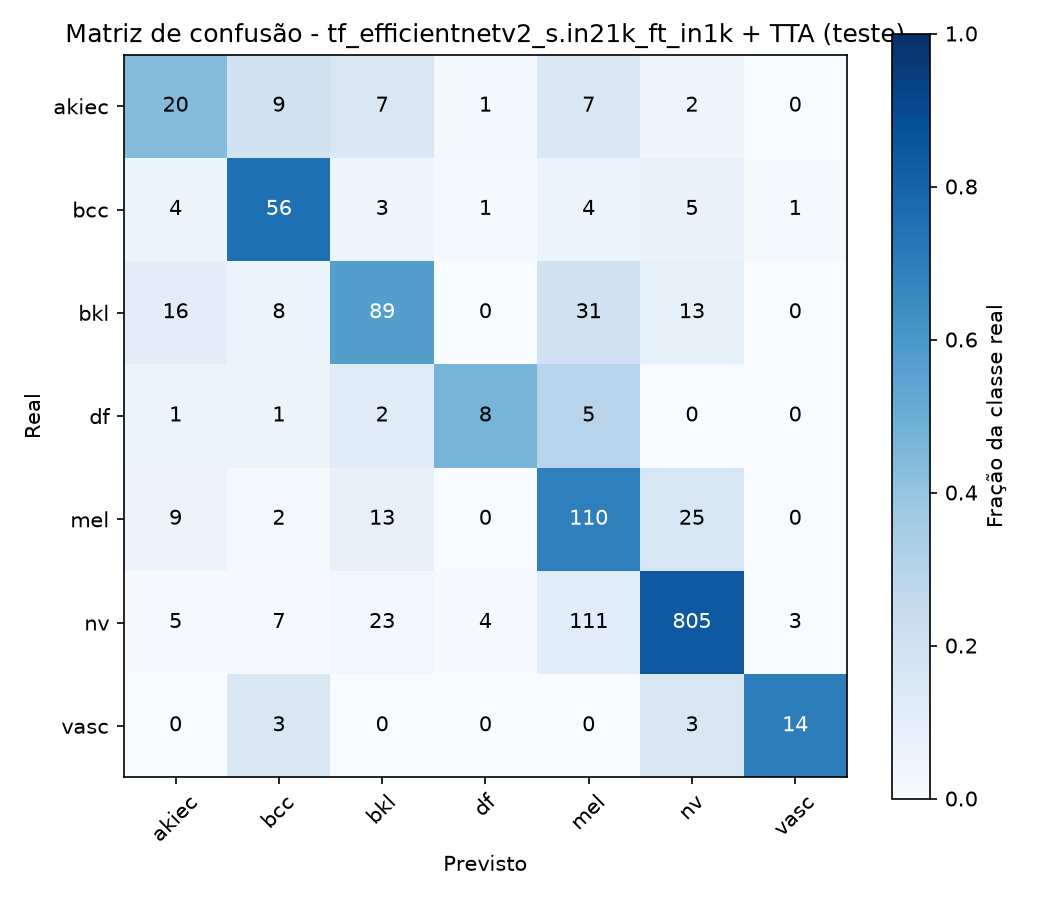

In [22]:
if use_saved:
    display(IPImage(filename=str(OUT / "baseline_confusion_matrix.png")))
else:
    cm = confusion_matrix(y_te, probs_te.argmax(1), labels=range(7))
    cm_norm = cm / cm.sum(axis=1, keepdims=True)

    fig, ax = plt.subplots(figsize=(7, 6))
    im = ax.imshow(cm_norm, cmap="Blues", vmin=0, vmax=1)
    ax.set_xticks(range(7)); ax.set_xticklabels(CLASSES, rotation=45)
    ax.set_yticks(range(7)); ax.set_yticklabels(CLASSES)
    for i in range(7):
        for j in range(7):
            ax.text(j, i, f"{cm[i, j]}", ha="center", va="center",
                    color="white" if cm_norm[i, j] > 0.5 else "black")
    ax.set_xlabel("Predicted"); ax.set_ylabel("True")
    ax.set_title(f"Confusion matrix - {BACKBONE} + TTA (test)")
    fig.colorbar(im, label="Fraction of the true class")
    fig.tight_layout()
    fig.savefig(OUT / "baseline_confusion_matrix.png", dpi=150)
    plt.show()

## 8. Saving the results

Two files are saved in the results folder:

- `baseline_head.pt`: weights of the linear layer, fitted temperature, classes, backbone name, feature dimension and number of views;
- `baseline_metrics.json`: test metrics. The top level holds the result **with TTA**; the **without TTA** result is stored under `sem_tta`.

The baseline metrics are the passive learning reference used in the learning curves of the active learning experiments.

In [24]:
if not use_saved:
    torch.save({"state_dict": head.state_dict(), "T": res_tta["temperatura"], "classes": CLASSES,
                "backbone": BACKBONE, "in_features": D, "n_views": int(X_te.shape[1])},
               OUT / "baseline_head.pt")
    with open(OUT / "baseline_metrics.json", "w", encoding="utf-8") as f:
        json.dump({**res_tta, "sem_tta": res_sem, "backbone": BACKBONE,
                   "n_views": int(X_te.shape[1])}, f, indent=2)
    print("Saved in:", OUT)
else:
    print("Results were loaded from", OUT)

Results were loaded from ..\results\results_baseline\results_tf_efficientnetv2_s.in21k_ft_in1k
